In [1]:
%load_ext autoreload
%autoreload 2

import hydra
import os
import datetime
from pathlib import Path

# Initialize hydra and move to the root of the repository
try:
    hydra.initialize(version_base=None, config_path="../config/")
    CONFIG = hydra.compose(config_name="main.yaml")
    print('Initializing hydra')
except:
    print('Hydra already initalized!')
else:
    os.chdir('..')
    OUTPUT_FOLDER = Path('output/{0}'.format(datetime.datetime.now()).replace(' ', '_'))
    Path(OUTPUT_FOLDER).mkdir(parents=True, exist_ok=True)

Initializing hydra


In [2]:
import cartopy.crs as ccrs
from src.plotting import (
    compute_shared_status_randomization,
    get_shared_status,
    governing_parties_histograms,
    plot_pooled_sample,
    plot_shared_status_randomized_communities,
    plot_temporal_evolution_of_governance,
    plot_temporal_network_statistics,
)
from src.temporal_network import TemporalNetwork
from src.weighted_network import WeightedNetwork

In [3]:
def load(year0=None, year1=None, edge_filter="S238"):
    input_path = Path(CONFIG.data.raw)
    nodes_file = input_path / CONFIG.data.filenames.nodes
    edges_file = input_path / CONFIG.data.filenames.edges
    return WeightedNetwork(
        nodes_file=nodes_file, edges_file=edges_file, year0=year0, year1=year1,
        edge_filter=edge_filter,
    )


def load_temporal(edge_filter="S238"):
    input_path = Path(CONFIG.data.raw)
    nodes_file = input_path / CONFIG.data.filenames.nodes
    edges_file = input_path / CONFIG.data.filenames.edges
    return TemporalNetwork(
        nodes_file=nodes_file, edges_file=edges_file, edge_filter=edge_filter
    )

In [4]:
G_WEIGHTED = load()
G_TEMPORAL = load_temporal()

CRS = ccrs.LambertAzimuthalEqualArea(
    central_latitude=CONFIG.grid.central_latitidue, 
    central_longitude=CONFIG.grid.central_longitude, 
    false_easting=CONFIG.grid.false_easting, 
    false_northing=CONFIG.grid.false_northing
)

Initializing weighted network...
Ignoring edges coded as S238
No time frame specified. Using full data.
Initalizing temporal network...
Ignoring edges coded as S238
Constructing networks...
Computing hamming distance...


## Main manuscript

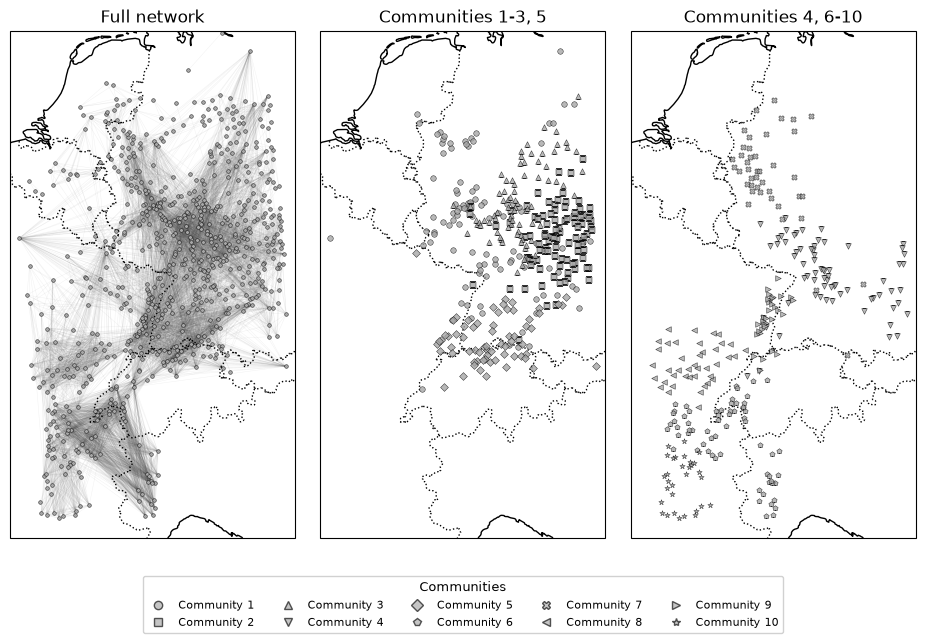

In [5]:
# Figure 1: pooled sample and community assignments
plot_pooled_sample(G_WEIGHTED, CRS, OUTPUT_FOLDER)

Years with significant changes: [1355 1415 1418]


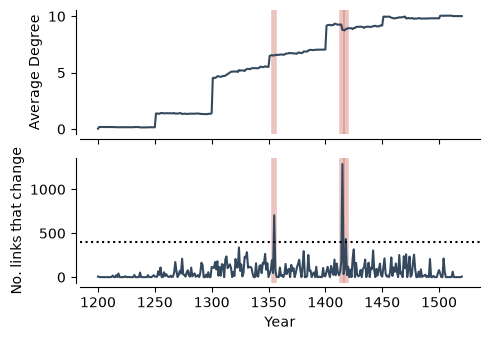

In [6]:
# Figure 2: temporal network statistics
plot_temporal_network_statistics(G_TEMPORAL, OUTPUT_FOLDER)

In [ ]:
shared_status = get_shared_status(G_WEIGHTED)
coherence_results = compute_shared_status_randomization(
    shared_status, G_WEIGHTED, key="coherence"
)

In [ ]:
# Figure 3: randomized community comparison
plot_shared_status_randomized_communities(
    coherence_results, OUTPUT_FOLDER, key="coherence", show_asterisks=False
)

## Appendix

In [ ]:
# Figure A1: temporal evolution of governance
plot_temporal_evolution_of_governance(G_WEIGHTED, OUTPUT_FOLDER)

In [ ]:
# Figure A2: governing parties by community
governing_parties_histograms(G_WEIGHTED, OUTPUT_FOLDER)